# Tasks: the fitness functions

A task turns what a robot did in a simulation (the path of its core, its final position, how long it took) into one number that evolution can optimise. ARIEL has three tasks: **gait learning** (how far or how fast does the robot move), **targeted locomotion** (how close does it get to a target; lower is better) and **turning in place** (how much does it turn without drifting away).

In this notebook the functions run on made-up paths whose right answer is obvious, then on one real physics run of the prebuilt gecko driven by a simple sine controller, next to the same gecko standing still. No graphics backend is needed.

In [1]:
# Standard library
import math
from typing import cast

In [2]:
# Third-party libraries
import matplotlib.pyplot as plt
import mujoco
import numpy as np
from rich.table import Table

In [3]:
# Local libraries
from ariel import console
from ariel.body_phenotypes.robogen_lite.prebuilt_robots import john_set
from ariel.parameters import FrozenModel
from ariel.simulation import SimpleFlatWorld
from ariel.simulation.tasks import (
    distance_to_target,
    turning_in_place,
    x_speed,
    xy_displacement,
    y_speed,
)
from ariel.simulation.tasks.targeted_locomotion import (
    fitness_delta_distance,
    fitness_direct_path,
    fitness_distance_and_efficiency,
    fitness_speed_to_target,
    fitness_survival_and_locomotion,
)

In [4]:
# Settings (the simulation is deterministic, so there is no seed)
TARGET = np.array([2.0, 0.0, 0.0])
START = np.array([0.0, 0.0, 0.1])
RUN_SECONDS = 5
FREQUENCY = 4.0  # Hz of the sine controller
RECORD_EVERY = 50  # steps between recorded positions

## Gait learning

`xy_displacement` is the straight distance between two points, `x_speed` and `y_speed` the speed along one axis (always positive). A 3-4-5 triangle gives the answer by hand.

In [5]:
start, end = (0.0, 0.0), (3.0, 4.0)
distance = xy_displacement(start, end)
along_x = x_speed(start, end, 2.0)
along_y = y_speed(start, end, 2.0)
console.print(f"displacement {distance}, x speed {along_x}, y speed {along_y}")
assert math.isclose(xy_displacement(start, end), 5.0)
assert math.isclose(x_speed(start, end, 2.0), 1.5)
assert math.isclose(y_speed(start, end, 2.0), 2.0)
assert math.isclose(x_speed(start, end, 0.0), 0.0)  # no time, no speed

displacement 5.0, x speed 1.5, y speed 2.0

## Turning in place

`turning_in_place` takes the path of a robot (a list of x, y points), adds up how much its heading changed, and divides by one plus how far it ended from where it started. A straight walk scores zero, a spin on the spot scores high, and a big circle scores in between because it drifts. The pictures show the three paths and their scores.

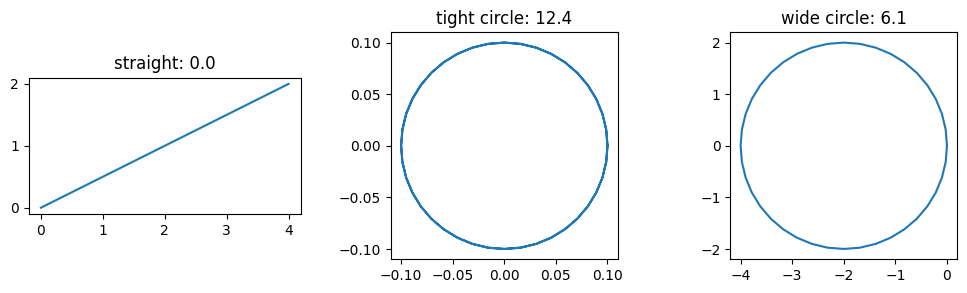

In [6]:
angles = np.linspace(0, 4 * np.pi, 81)  # two turns
paths = {
    "straight": [(float(t), 0.5 * float(t)) for t in np.linspace(0, 4, 81)],
    "tight circle": [
        (0.1 * float(np.cos(a)), 0.1 * float(np.sin(a))) for a in angles
    ],
    "wide circle": [
        (2 * float(np.cos(a)) - 2, 2 * float(np.sin(a))) for a in angles[:41]
    ],
}
scores = {name: turning_in_place(path) for name, path in paths.items()}
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for axis, (name, path) in zip(axes, paths.items(), strict=True):
    axis.plot(*zip(*path, strict=True))
    axis.set_aspect("equal")
    axis.set_title(f"{name}: {scores[name]:.1f}")
plt.tight_layout()
plt.show()

In [7]:
assert math.isclose(scores["straight"], 0.0, abs_tol=1e-9)
assert scores["tight circle"] > scores["wide circle"] > scores["straight"]
assert math.isclose(turning_in_place([(0.0, 0.0)]), 0.0)  # too short to turn

## Targeted locomotion

The robot starts at the origin and the target is two metres ahead. Every function here is a cost: **lower is better**. The table scores four made-up outcomes with every variant. `distance_to_target` is the simplest (remaining distance); the others add the progress made, the control effort, the wasted path, survival and the time to arrive.

In [8]:
class Outcome(FrozenModel):
    """Where a made-up run ended and what it cost."""

    final: tuple[float, float, float]
    path: float
    effort: float
    z: float
    time: float | None


outcomes = {
    "arrived": Outcome(
        final=(2.0, 0.0, 0.1), path=2.0, effort=100.0, z=0.1, time=3.0
    ),
    "halfway": Outcome(
        final=(1.0, 0.0, 0.1), path=1.0, effort=100.0, z=0.1, time=None
    ),
    "wrong way": Outcome(
        final=(-1.0, 0.0, 0.1), path=1.0, effort=100.0, z=0.1, time=None
    ),
    "sank": Outcome(
        final=(2.0, 0.0, 0.0), path=2.0, effort=100.0, z=0.01, time=3.0
    ),
}
DURATION = 10.0
SINK_PENALTY = 10.0
rows = {}
for name, o in outcomes.items():
    final = np.array(o.final)
    closest = distance_to_target(final, TARGET)
    rows[name] = {
        "distance": closest,
        "delta": fitness_delta_distance(START, final, TARGET),
        "effort": fitness_distance_and_efficiency(
            START, final, TARGET, o.effort
        ),
        "survival": fitness_survival_and_locomotion(START, final, TARGET, o.z),
        "direct path": fitness_direct_path(START, final, TARGET, o.path),
        "speed": fitness_speed_to_target(o.time, DURATION, closest),
    }
table = Table(title="Targeted locomotion (lower is better)")
table.add_column("outcome")
for function in next(iter(rows.values())):
    table.add_column(function, justify="right")
for name, values in rows.items():
    table.add_row(name, *(f"{v:.2f}" for v in values.values()))
console.print(table)

                  Targeted locomotion (lower is better)                   
┏━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━┳━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━┓
┃ outcome   ┃ distance ┃ delta ┃ effort ┃ survival ┃ direct path ┃ speed ┃
┡━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━╇━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━┩
│ arrived   │     0.00 │ -2.00 │  -1.90 │    -2.00 │       -2.00 │  0.30 │
│ halfway   │     1.00 │ -1.00 │  -0.90 │    -1.00 │       -1.00 │  2.00 │
│ wrong way │     3.00 │  1.00 │   1.10 │     1.00 │        1.00 │  4.00 │
│ sank      │     0.00 │ -2.00 │  -1.90 │    10.00 │       -2.00 │  0.30 │
└───────────┴──────────┴───────┴────────┴──────────┴─────────────┴───────┘

In [9]:
for function in rows["arrived"]:
    if function == "survival":
        continue
    assert (
        rows["arrived"][function]
        < rows["halfway"][function]
        < rows["wrong way"][function]
    ), function
assert math.isclose(rows["sank"]["survival"], SINK_PENALTY)
assert (
    rows["arrived"]["speed"] <= 1.0 < rows["halfway"]["speed"]
)  # arrived: in [0, 1]; not arrived: above 1

## One real run

The gecko is spawned in a flat world and driven for five seconds by a sine on every joint, each shifted by a quarter turn from the previous one. Nothing here is a good gait; the point is that the task functions read a real path. A second gecko gets no control. MuJoCo is deterministic, so the numbers repeat.

Look at the *turning* column: even the gecko that stands still scores above zero, because its position wobbles by a few micrometres and `turning_in_place` reads a heading from every tiny step. The score only means something for a robot that really moves.

In [10]:
def run(amplitude: float) -> tuple[list[tuple[float, float]], float, float]:
    world = SimpleFlatWorld(load_precompiled=False)
    world.spawn(john_set.gecko_small().spec)
    model = cast("mujoco.MjModel", world.spec.compile())
    data = mujoco.MjData(model)
    steps = int(RUN_SECONDS / model.opt.timestep)
    path, lowest, effort = [], 9.0, 0.0
    for step in range(steps):
        time = step * model.opt.timestep
        phases = np.arange(model.nu) * np.pi / 2
        data.ctrl[:] = amplitude * np.sin(2 * np.pi * FREQUENCY * time + phases)
        effort += float(np.abs(data.ctrl).sum())
        mujoco.mj_step(model, data)
        lowest = min(lowest, float(data.qpos[2]))
        if step % RECORD_EVERY == 0:
            path.append((float(data.qpos[0]), float(data.qpos[1])))
    return path, lowest, effort


idle_path, idle_low, idle_effort = run(0.0)
driven_path, driven_low, driven_effort = run(1.5)

In [11]:
table = Table(title=f"Gecko, {RUN_SECONDS} s")
for column in (
    "run",
    "displacement (m)",
    "turning",
    "distance to target (m)",
    "lowest core z (m)",
):
    table.add_column(column, justify="right")
for name, path, low in (
    ("idle", idle_path, idle_low),
    ("driven", driven_path, driven_low),
):
    final = np.array([*path[-1], 0.1])
    table.add_row(
        name,
        f"{xy_displacement(path[0], path[-1]):.4f}",
        f"{turning_in_place(path):.2f}",
        f"{distance_to_target(final, TARGET):.3f}",
        f"{low:.3f}",
    )
console.print(table)

                                     Gecko, 5 s                                     
┏━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃    run ┃ displacement (m) ┃ turning ┃ distance to target (m) ┃ lowest core z (m) ┃
┡━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│   idle │           0.0000 │   21.99 │                  2.000 │             0.098 │
│ driven │           0.0298 │   92.80 │                  1.970 │             0.097 │
└────────┴──────────────────┴─────────┴────────────────────────┴───────────────────┘

In [12]:
idle_move = xy_displacement(idle_path[0], idle_path[-1])
driven_move = xy_displacement(driven_path[0], driven_path[-1])
assert idle_effort <= 0.0
assert driven_effort > 0.0
assert driven_move > idle_move  # driving moves it more than standing still
assert min(idle_low, driven_low) > 0.0  # it never fell through the floor
assert math.isfinite(turning_in_place(driven_path))